In [1]:
# Cell 1: 依赖库导入
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

# Mesa 核心组件导入 (适配 Mesa 3.x 及以上版本)
import mesa
from mesa import Agent, Model
from mesa.space import SingleGrid
from mesa.datacollection import DataCollector

# 设置随机种子以保证实验可复现性（调试时可用，若要随机可设为 None）
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("✅ Cell 1: 依赖库导入完成，Mesa 版本:", mesa.__version__)

✅ Cell 1: 依赖库导入完成，Mesa 版本: 3.3.1


In [2]:
# Cell 2: 全局超级参数配置中心
# ==============================================================================
# 1. 空间与地图参数 (Environment & Spatial Config)
# ==============================================================================
GRID_WIDTH = 100               # 网格宽度 (X轴)
GRID_HEIGHT = 100              # 网格高度 (Y轴)
EAST_BOUNDARY_X = 50           # 东部高资源区划分线 (X >= 50 为东部)

RESOURCE_SPAWN_PROB = 0.08     # 每一轮全图每个空格子刷新资源的概率
BASE_RESOURCE_VAL = 10         # 西部(左侧)空格子刷新的基础资源量
EAST_RESOURCE_MULTIPLIER = 1.5 # 东部(右侧)资源的倍率 n (例如 1.5 代表多 50% 资源)
TECH_BOOST_RATIO = 0.20        # 科学发现触发后，全局资源刷新上限的提升比例 (+20%)

# ==============================================================================
# 2. Population 规模与五类人格初始配置 (Population & Archetype Distribution)
# ==============================================================================
INIT_AGENTS_COUNT = 100        # 初始生成的 Agent 总数

# 五类人格在初始种群中的分布比例权重 (占比之和不要求强行等于1，系统会自动归一化)
ARCHETYPE_RATIOS = {
    "Social_Darwinist": 0.15,   # 社会达尔文主义者
    "Moral_Artist":     0.15,   # 道德表演艺术家
    "Ruffian":           0.15,   # 打手 / 暴徒
    "Mob":               0.45,   # 庸众 / 暴民
    "Hermit_Sage":       0.10    # 隐士 / 智者
}

# 五类人格的属性点分配基准 [Int, Inf, Mor, Imp_V, Exp_V, Exp_T]
# 数值范围: [0, 100]，在生成 Agent 时会在此基准上叠加 ±5 的随机浮动
ARCHETYPE_BASE_STATS = {
    "Social_Darwinist": {"int": 85, "inf": 80, "mor": 20, "imp_v": 90, "exp_v": 15, "exp_t": 40},
    "Moral_Artist":     {"int": 60, "inf": 90, "mor": 30, "imp_v": 20, "exp_v": 5,  "exp_t": 20},
    "Ruffian":           {"int": 30, "inf": 30, "mor": 10, "imp_v": 30, "exp_v": 90, "exp_t": 5},
    "Mob":               {"int": 40, "inf": 40, "mor": 50, "imp_v": 40, "exp_v": 40, "exp_t": 15},
    "Hermit_Sage":       {"int": 90, "inf": 20, "mor": 80, "imp_v": 5,  "exp_v": 5,  "exp_t": 90}
}

# ==============================================================================
# 3. 生存、生命周期与移动参数 (Survival, Lifecycle & Movement)
# ==============================================================================
INIT_RESOURCE_PER_AGENT = 100  # Agent 创角时的初始资源量
BASE_CONSUMPTION = 2           # 每个 Agent 每一轮固定的基础生存消耗 (C_base)
MOVE_STEP_LIMIT = 5            # Agent 每一轮可移动的最长曼哈顿距离 (5 或 10 格)

STARVE_LIMIT_STEPS = 10        # 资源 <= 0 后，连续饿肚子 N 轮则破产死亡
RETIRE_AGE_STEPS = 6000        # 自然衰老起点轮数 (60岁，假设 100 轮/岁)
OLD_AGE_DEATH_PROB = 0.01      # 超过 60 岁后，每一轮按此基础概率递增衰老死亡

# ==============================================================================
# 4. Phase 1 局部资源争夺与 Phase 2 进阶动作参数 (Phase 1 & Phase 2 Game Engine)
# ==============================================================================
# Phase 1 局部 3x3 网格竞拍的智力与影响力权重
WEIGHT_INT_RATIO = 0.6         # 竞拍权重中智力的比重
WEIGHT_INF_RATIO = 0.4         # 竞拍权重中影响力的比重

# Phase 2 掠夺机制参数
STEAL_BASE_RATIO = 0.3         # 掠夺成功时，默认基础掠夺对方资产的比例 (30%)
EXPLICIT_VIOLENCE_CRIT_MULT = 2.0 # 显性暴力触发暴击时掠夺量翻倍系数
PUNISH_PROB_EXPLICIT = 0.30    # 高显性暴力行为触发“法律/集体反抗”惩罚的概率
PUNISH_PENALTY_RATIO = 0.50    # 触发法律惩罚时，一次性扣除当前资产的比例 (50%)

# Phase 2 科学发现/科研参数
TECH_PROGRESS_THRESHOLD = 500  # 全局科研进度条蓄满阈值，蓄满即触发一次科学发现

# ==============================================================================
# 5. Phase 3 社会关系参数 (Phase 3 Social Interactions)
# ==============================================================================
# 婚姻与繁殖
MARRY_RESOURCE_MIN = 150       # 发起结婚的最低个人资源门槛
BREED_RESOURCE_MIN = 300       # 夫妻总资源达到此阈值可触发繁殖
BREED_COST_RATIO = 0.30        # 繁殖时扣除夫妻总资产的 30% 作为抚养费
DIVORCE_COOLDOWN_STEPS = 50    # 离婚后的再婚冷却期 (轮数)
GENIUS_MUTATION_PROB = 0.01    # 子代产生单一属性爆表 (+30) 的天才突变概率

# 联盟与内耗
MAX_ALLIANCE_MEMBERS = 8       # 一个小团体/联盟的最大人数上限
ALLIANCE_BASE_COST = 1.0       # 联盟基础维护费 (每多一人按 Size^1.5 增加)
ALLIANCE_MORAL_FRICTION = 0.05 # 联盟内部成员道德差值产生的内耗扣减系数

# 追随者与保护伞
PROTECTION_FEE_RATIO = 0.10    # 追随者每轮上缴给保护者/联盟的资源比例 α (10%)
PROTECTION_DEFENSE_FACTOR = 0.90# 追随者受到掠夺时，借用保护者属性的折扣系数 (90%)
FAILURE_REPUTATION_PENALTY = 5.0# 保护伞保护失败时，保护者 Influence 永久下降值

print("✅ Cell 2: 全局超级参数配置中心载入成功！所有变量已注册。")

✅ Cell 2: 全局超级参数配置中心载入成功！所有变量已注册。


In [3]:
# Cell 3: 社交网络与信息通讯数据结构
# ==============================================================================

class SocialNetwork:
    """
    维护 Agent 之间的社交图谱，处理信息共享、信任度以及关系拓扑
    关系类型包括: 'marriage' (婚姻), 'alliance' (联盟), 'kinship' (亲属), 'follower' (追随)
    """
    def __init__(self):
        self.graph = nx.Graph()

    def add_agent(self, agent_id):
        """将 Agent 注册到社交网络"""
        if not self.graph.has_node(agent_id):
            self.graph.add_node(agent_id)

    def remove_agent(self, agent_id):
        """Agent 死亡时从网络中移除"""
        if self.graph.has_node(agent_id):
            self.graph.remove_node(agent_id)

    def add_relation(self, agent_a_id, agent_b_id, relation_type):
        """添加或更新关系"""
        self.add_agent(agent_a_id)
        self.add_agent(agent_b_id)
        self.graph.add_edge(agent_a_id, agent_b_id, type=relation_type)

    def remove_relation(self, agent_a_id, agent_b_id, relation_type=None):
        """移除指定关系"""
        if self.graph.has_edge(agent_a_id, agent_b_id):
            if relation_type is None or self.graph[agent_a_id][agent_b_id].get('type') == relation_type:
                self.graph.remove_edge(agent_a_id, agent_b_id)

    def get_relatives_and_allies(self, agent_id):
        """获取强社交圈（配偶、盟友、父母与子女），用于信息共享广播"""
        if not self.graph.has_node(agent_id):
            return []
        
        close_ids = []
        for neighbor in self.graph.neighbors(agent_id):
            edge_type = self.graph[agent_id][neighbor].get('type')
            if edge_type in ['marriage', 'alliance', 'kinship']:
                close_ids.append(neighbor)
        return close_ids

    def broadcast_resource_info(self, source_agent, target_pos, model):
        """
        关系圈“信息通讯”补丁:
        当 source_agent 发现高浓度资源格时，向配偶、盟友和直系亲属广播坐标
        """
        close_ids = self.get_relatives_and_allies(source_agent.unique_id)
        for target_id in close_ids:
            # 找到对应的 Agent 对象并更新其“记忆导航目标”
            if target_id in model.agents_dict:
                ally = model.agents_dict[target_id]
                # 只有当对方当前没有更优目标时才更新导航目标
                if ally.known_high_resource_pos is None:
                    ally.known_high_resource_pos = target_pos

print("✅ Cell 3: 社交网络与信息通讯模块载入成功！")

✅ Cell 3: 社交网络与信息通讯模块载入成功！


In [4]:
# Cell 4: Agent 核心类定义 (SocialAgent) - 修复版
# ==============================================================================
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="mesa") # 屏蔽 Mesa 内部重复放置的非致命提示

class SocialAgent(Agent):
    """
    具备 6 维属性向量、状态机与三阶段动作流的智能体
    """
    def __init__(self, model, archetype, pos=None):
        super().__init__(model)
        self.archetype = archetype  # 人格类型名
        
        # 1. 资源与生命周期初始化
        self.resources = INIT_RESOURCE_PER_AGENT
        self.age = 0                # 年龄（轮数）
        self.starve_steps = 0       # 连续饥饿轮数
        self.is_alive = True
        
        # 2. 6 维核心属性向量 (基础值 + 随机浮动 ±5，限制在 [1, 100])
        base_stats = ARCHETYPE_BASE_STATS[archetype]
        self.int = int(np.clip(base_stats["int"] + random.randint(-5, 5), 1, 100))
        self.inf = int(np.clip(base_stats["inf"] + random.randint(-5, 5), 1, 100))
        self.mor = int(np.clip(base_stats["mor"] + random.randint(-5, 5), 1, 100))
        self.imp_v = int(np.clip(base_stats["imp_v"] + random.randint(-5, 5), 1, 100))
        self.exp_v = int(np.clip(base_stats["exp_v"] + random.randint(-5, 5), 1, 100))
        self.exp_t = int(np.clip(base_stats["exp_t"] + random.randint(-5, 5), 1, 100))

        # 3. 社交状态标记
        self.spouse_id = None            # 配偶 unique_id
        self.divorce_cooldown = 0        # 离婚冷却期
        self.alliance_id = None          # 所属联盟 ID
        self.leader_id = None            # 追随的大佬 unique_id
        self.followers = []              # 追随自己的 follower unique_id 列表
        self.children = []               # 子女 unique_id 列表
        self.parents = []                # 父母 unique_id 列表
        
        # 4. 导航记忆与 Buff 状态
        self.known_high_resource_pos = None  # 共享获取的高资源格坐标

    # --------------------------------------------------------------------------
    # 属性与 Buff 动态计算
    # --------------------------------------------------------------------------
    @property
    def effective_int(self):
        """婚姻协同 Buff: 低属性方获得配偶溢出加成 (婚姻期间有效)"""
        bonus = 0
        if self.spouse_id and self.spouse_id in self.model.agents_dict:
            spouse = self.model.agents_dict[self.spouse_id]
            if spouse.int > self.int:
                bonus = int((spouse.int - self.int) * 0.3)
        return min(100, self.int + bonus)

    @property
    def effective_inf(self):
        """婚姻协同 Buff: 影响力加成"""
        bonus = 0
        if self.spouse_id and self.spouse_id in self.model.agents_dict:
            spouse = self.model.agents_dict[self.spouse_id]
            if spouse.inf > self.inf:
                bonus = int((spouse.inf - self.inf) * 0.3)
        return min(100, self.inf + bonus)

    # --------------------------------------------------------------------------
    # 行为偏好计算
    # --------------------------------------------------------------------------
    def get_explore_preference(self):
        """
        计算 Phase 2 选择【探索】还是【掠夺】的概率
        P(探索) = Exploration / (Exploration + 100 - Morality)
        """
        explore_score = self.exp_t
        predate_score = (100 - self.mor) + 0.1  # 防止分母为 0
        p_explore = explore_score / (explore_score + predate_score)
        return p_explore

    def get_auction_weight(self):
        """Phase 1 局部 3x3 竞拍争夺权重: Int * 0.6 + Inf * 0.4"""
        return self.effective_int * WEIGHT_INT_RATIO + self.effective_inf * WEIGHT_INF_RATIO

    # --------------------------------------------------------------------------
    # 周期状态更新
    # --------------------------------------------------------------------------
    def update_lifecycle(self):
        """每一轮更新年龄、消耗生存资源以及冷却状态"""
        self.age += 1
        self.resources -= BASE_CONSUMPTION
        
        # 扣减离婚冷却时间
        if self.divorce_cooldown > 0:
            self.divorce_cooldown -= 1
            
        # 检查饥饿状态
        if self.resources <= 0:
            self.starve_steps += 1
        else:
            self.starve_steps = 0  # 恢复正常

print("✅ Cell 4: SocialAgent 核心类修复完成！")

✅ Cell 4: SocialAgent 核心类修复完成！


In [5]:
# Cell 5: Agent 三阶段动作逻辑实现 - 修复 UnboundLocalError
# ==============================================================================

def agent_phase_1_move_and_collect(self):
    """Phase 1: 导航移动与局部 3x3 资源竞拍"""
    if not self.is_alive or self.pos is None:
        return

    # 1.1 寻路导航策略 (优先向共享导航点移动，否则向东部高资源区移动)
    target_pos = None
    if self.known_high_resource_pos:
        target_pos = self.known_high_resource_pos
    elif self.pos[0] < EAST_BOUNDARY_X:
        target_pos = (random.randint(EAST_BOUNDARY_X, GRID_WIDTH - 1), random.randint(0, GRID_HEIGHT - 1))

    # 在 MOVE_STEP_LIMIT 曼哈顿距离内选择最优移动位置
    possible_steps = self.model.grid.get_neighborhood(
        self.pos, moore=True, include_center=True, radius=MOVE_STEP_LIMIT
    )
    empty_steps = [p for p in possible_steps if self.model.grid.is_cell_empty(p) or p == self.pos]

    if empty_steps:
        if target_pos:
            best_step = min(empty_steps, key=lambda p: abs(p[0]-target_pos[0]) + abs(p[1]-target_pos[1]))
        else:
            best_step = random.choice(empty_steps)
        
        if best_step != self.pos:
            self.model.grid.move_agent(self, best_step)

    # 到达目的地后重置导航目标
    if self.known_high_resource_pos and self.pos == self.known_high_resource_pos:
        self.known_high_resource_pos = None

    # 1.2 局部 3x3 资源竞拍收集
    neighbors_3x3 = self.model.grid.get_neighborhood(self.pos, moore=True, include_center=True, radius=1)
    for cell in neighbors_3x3:
        # 修复关键点：提取 grid_res 到最外层，确保变量始终存在
        grid_res = self.model.grid_resources.get(cell, 0)
        
        if grid_res > 0:
            cell_agents = [a for a in self.model.grid.get_cell_list_contents(cell) if a.is_alive]
            if cell_agents:
                total_weight = sum(a.get_auction_weight() for a in cell_agents)
                if total_weight > 0:
                    my_share = grid_res * (self.get_auction_weight() / total_weight)
                    self.resources += my_share
                    
                    # 清空/扣减该格资源（由最后一个处理的 agent 清空）
                    if self == cell_agents[-1]:
                        self.model.grid_resources[cell] = 0

            # 信息广播补丁：只有格子里确实有高资源时才广播
            if grid_res >= BASE_RESOURCE_VAL * 2:
                self.model.social_net.broadcast_resource_info(self, cell, self.model)

def agent_phase_2_game_action(self):
    """Phase 2: 进阶动作（探索发现 vs 尝试掠夺）"""
    if not self.is_alive or self.pos is None:
        return

    p_explore = self.get_explore_preference()
    if random.random() < p_explore:
        # --- 选项 A: 探索科研 ---
        tech_contrib = (self.effective_int * self.exp_t) / 100.0
        self.model.global_tech_progress += tech_contrib
    else:
        # --- 选项 B: 尝试掠夺 ---
        neighbors = self.model.grid.get_neighbors(self.pos, moore=True, include_center=False, radius=1)
        potential_victims = [
            a for a in neighbors if a.is_alive 
            and a.unique_id != self.spouse_id 
            and a.alliance_id != self.alliance_id
            and a.leader_id != self.unique_id
        ]
        
        if potential_victims:
            victim = min(potential_victims, key=lambda a: a.effective_int) # 挑选最弱者
            
            victim_def_stat = victim.effective_int
            protector = None
            if victim.leader_id and victim.leader_id in self.model.agents_dict:
                protector = self.model.agents_dict[victim.leader_id]
                victim_def_stat = max(victim.effective_int, int(protector.effective_int * PROTECTION_DEFENSE_FACTOR))

            my_attack = self.effective_int + self.imp_v
            if my_attack > victim_def_stat:
                steal_ratio = STEAL_BASE_RATIO * (1.0 - self.mor / 100.0)
                if random.random() < (self.exp_v / 100.0):
                    steal_ratio *= EXPLICIT_VIOLENCE_CRIT_MULT
                
                stolen_amount = victim.resources * steal_ratio
                victim.resources -= stolen_amount
                self.resources += stolen_amount

                if protector and victim_def_stat > victim.effective_int:
                    protector.inf = max(1, protector.inf - FAILURE_REPUTATION_PENALTY)

            if random.random() < (self.exp_v / 100.0) * PUNISH_PROB_EXPLICIT:
                penalty = self.resources * PUNISH_PENALTY_RATIO
                self.resources -= penalty

def agent_phase_3_social_action(self):
    """Phase 3: 社会关系动作 (婚姻/离婚/结盟/追随)"""
    if not self.is_alive or self.pos is None:
        return

    # 3.1 离婚检查
    if self.spouse_id and self.spouse_id in self.model.agents_dict:
        spouse = self.model.agents_dict[self.spouse_id]
        if self.mor < 30 and (self.resources < spouse.resources * 0.3):
            self.model.social_net.remove_relation(self.unique_id, self.spouse_id, 'marriage')
            spouse.spouse_id = None
            self.spouse_id = None
            self.divorce_cooldown = DIVORCE_COOLDOWN_STEPS
            spouse.divorce_cooldown = DIVORCE_COOLDOWN_STEPS
            total_res = self.resources + spouse.resources
            self.resources = total_res / 2.0
            spouse.resources = total_res / 2.0

    # 3.2 结婚与繁殖检查
    if not self.spouse_id and self.divorce_cooldown == 0 and self.resources >= MARRY_RESOURCE_MIN:
        neighbors = self.model.grid.get_neighbors(self.pos, moore=True, include_center=False, radius=1)
        single_candidates = [
            a for a in neighbors if a.is_alive and not a.spouse_id 
            and a.divorce_cooldown == 0 and a.resources >= MARRY_RESOURCE_MIN
        ]
        if single_candidates:
            partner = random.choice(single_candidates)
            self.spouse_id = partner.unique_id
            partner.spouse_id = self.unique_id
            self.model.social_net.add_relation(self.unique_id, partner.unique_id, 'marriage')

    # 已婚则判定繁殖
    if self.spouse_id and self.spouse_id in self.model.agents_dict:
        spouse = self.model.agents_dict[self.spouse_id]
        if (self.resources + spouse.resources) >= BREED_RESOURCE_MIN:
            cost = (self.resources + spouse.resources) * BREED_COST_RATIO
            self.resources -= cost / 2.0
            spouse.resources -= cost / 2.0
            self.model.breed_child(self, spouse)

    # 3.3 追随者上缴保护费
    if self.leader_id and self.leader_id in self.model.agents_dict:
        leader = self.model.agents_dict[self.leader_id]
        fee = self.resources * PROTECTION_FEE_RATIO
        self.resources -= fee
        leader.resources += fee
    elif not self.leader_id and self.inf < 40 and not self.alliance_id:
        neighbors = self.model.grid.get_neighbors(self.pos, moore=True, include_center=False, radius=2)
        leaders = [a for a in neighbors if a.is_alive and a.inf >= 70 and a.unique_id != self.unique_id]
        if leaders:
            big_boss = max(leaders, key=lambda a: a.inf)
            self.leader_id = big_boss.unique_id
            big_boss.followers.append(self.unique_id)
            self.model.social_net.add_relation(self.unique_id, big_boss.unique_id, 'follower')

# 挂载方法
SocialAgent.phase_1_move_and_collect = agent_phase_1_move_and_collect
SocialAgent.phase_2_game_action = agent_phase_2_game_action
SocialAgent.phase_3_social_action = agent_phase_3_social_action

print("✅ Cell 5: 作用域与安全检查修复完成！")

✅ Cell 5: 作用域与安全检查修复完成！


In [6]:
# Cell 6: 主模型类定义 (SocialModel) - 修复 Mesa 3.x find_empty 兼容性
# ==============================================================================

class SocialModel(Model):
    """
    仿真主控模型: 负责网格刷新、技术突破、生老病死清算与数据统计
    """
    def __init__(self):
        super().__init__()
        self.grid = SingleGrid(GRID_WIDTH, GRID_HEIGHT, torus=False)
        self.social_net = SocialNetwork()
        
        # 状态索引与跟踪
        self.agents_dict = {}
        self.grid_resources = {}          # (x, y) -> 资源量
        self.global_tech_progress = 0     # 全局科研进度
        self.tech_boost_active = False    # 是否触发了科学突破 Buff
        self.alliance_counter = 0         # 联盟编号分配器

        # 1. 按比例初始化 Agent 并散布地图
        archetypes = list(ARCHETYPE_RATIOS.keys())
        weights = list(ARCHETYPE_RATIOS.values())
        norm_weights = [w / sum(weights) for w in weights]

        # 预先获取全图所有可用坐标并打乱
        all_positions = [(x, y) for x in range(GRID_WIDTH) for y in range(GRID_HEIGHT)]
        random.shuffle(all_positions)

        for i in range(min(INIT_AGENTS_COUNT, len(all_positions))):
            arch = np.random.choice(archetypes, p=norm_weights)
            pos = all_positions[i]  # 安全分配不重复的格子
            
            agent = SocialAgent(self, arch, pos)
            self.grid.place_agent(agent, pos)
            self.agents_dict[agent.unique_id] = agent
            self.social_net.add_agent(agent.unique_id)

    def get_random_empty_pos(self):
        """兼容 Mesa 各版本的安全空格子查找工具函数"""
        # 如果 Mesa 版本支持 grid.empties，直接从中随机选一个
        if hasattr(self.grid, 'empties') and self.grid.empties:
            return random.choice(list(self.grid.empties))
        
        # 兜底算法：遍历查找当前为空的坐标
        empty_cells = [
            (x, y) for x in range(GRID_WIDTH) for y in range(GRID_HEIGHT) 
            if self.grid.is_cell_empty((x, y))
        ]
        return random.choice(empty_cells) if empty_cells else None

    def spawn_resources(self):
        """非对称地图资源刷新机制"""
        tech_multiplier = (1.0 + TECH_BOOST_RATIO) if self.tech_boost_active else 1.0
        
        for x in range(GRID_WIDTH):
            for y in range(GRID_HEIGHT):
                # 只有未被 Agent 占据的空格子才刷新资源
                if self.grid.is_cell_empty((x, y)):
                    if random.random() < RESOURCE_SPAWN_PROB:
                        base_val = BASE_RESOURCE_VAL
                        if x >= EAST_BOUNDARY_X:
                            base_val *= EAST_RESOURCE_MULTIPLIER
                        
                        spawn_amount = base_val * tech_multiplier * random.uniform(0.8, 1.2)
                        self.grid_resources[(x, y)] = self.grid_resources.get((x, y), 0) + spawn_amount

    def breed_child(self, parent1, parent2):
        """生成子代 Agent 并进行遗传与突变"""
        empty_pos = self.get_random_empty_pos()
        if not empty_pos:
            return  # 网格全满无法生育
            
        # 确定子代 Archetype (继承父母之一或概率为庸众)
        child_arch = random.choice([parent1.archetype, parent2.archetype, "Mob"])
        child = SocialAgent(self, child_arch, empty_pos)
        
        # 属性遗传：父母均值 ± 随机波动
        stats = ["int", "inf", "mor", "imp_v", "exp_v", "exp_t"]
        for stat in stats:
            p1_val = getattr(parent1, stat)
            p2_val = getattr(parent2, stat)
            inherited = int((p1_val + p2_val) / 2.0 + random.randint(-10, 10))
            
            # 1% 天才突变概率
            if random.random() < GENIUS_MUTATION_PROB:
                inherited += 30
                
            setattr(child, stat, int(np.clip(inherited, 1, 100)))

        # 维护亲属关系网络
        parent1.children.append(child.unique_id)
        parent2.children.append(child.unique_id)
        child.parents = [parent1.unique_id, parent2.unique_id]
        self.social_net.add_relation(parent1.unique_id, child.unique_id, 'kinship')
        self.social_net.add_relation(parent2.unique_id, child.unique_id, 'kinship')

        self.grid.place_agent(child, empty_pos)
        self.agents_dict[child.unique_id] = child

    def handle_death_and_inheritance(self, agent):
        """处理破产饿死/老死与财产继承"""
        agent.is_alive = False
        self.grid.remove_agent(agent)
        
        # 遗产分配逻辑：平分给配偶与子女
        beneficiaries = []
        if agent.spouse_id and agent.spouse_id in self.agents_dict and self.agents_dict[agent.spouse_id].is_alive:
            beneficiaries.append(self.agents_dict[agent.spouse_id])
        for cid in agent.children:
            if cid in self.agents_dict and self.agents_dict[cid].is_alive:
                beneficiaries.append(self.agents_dict[cid])

        if beneficiaries and agent.resources > 0:
            share = agent.resources / len(beneficiaries)
            for b in beneficiaries:
                b.resources += share

        # 从网络和字典中注销
        self.social_net.remove_agent(agent.unique_id)
        del self.agents_dict[agent.unique_id]

    def step(self):
        """时钟推进一轮 (1 Step)"""
        # 1. 刷新环境资源
        self.spawn_resources()

        # 2. 检查科学发现进度
        if self.global_tech_progress >= TECH_PROGRESS_THRESHOLD:
            self.tech_boost_active = True

        # 获取所有活着的 Agent 引用
        active_agents = [a for a in list(self.agents_dict.values()) if a.is_alive]
        random.shuffle(active_agents) # 打乱顺序防止策略偏置

        # 3. 依次调度 Agent 执行 Phase 1, Phase 2, Phase 3
        for agent in active_agents:
            agent.update_lifecycle()
            agent.phase_1_move_and_collect()

        for agent in active_agents:
            agent.phase_2_game_action()

        for agent in active_agents:
            agent.phase_3_social_action()

        # 4. 死亡清算 (破产饿死或衰老死亡)
        for agent in active_agents:
            if agent.starve_steps >= STARVE_LIMIT_STEPS:
                self.handle_death_and_inheritance(agent)
            elif agent.age >= RETIRE_AGE_STEPS:
                death_prob = OLD_AGE_DEATH_PROB * (1 + (agent.age - RETIRE_AGE_STEPS) / 100.0)
                if random.random() < death_prob:
                    self.handle_death_and_inheritance(agent)

print("✅ Cell 6: 主模型 SocialModel 修复完成并载入成功！")

✅ Cell 6: 主模型 SocialModel 修复完成并载入成功！


In [7]:
# Cell 7: DataCollector 数据统计与指标计算
# ==============================================================================

def compute_gini(model):
    """计算当前活着 Agent 的财富基尼系数 (Gini Coefficient)"""
    resources = [a.resources for a in model.agents_dict.values() if a.is_alive and a.resources > 0]
    if not resources or len(resources) < 2:
        return 0.0
    
    array = np.array(resources, dtype=np.float64)
    array = np.sort(array)
    index = np.arange(1, array.shape[0] + 1)
    n = array.shape[0]
    return float((np.sum((2 * index - n - 1) * array)) / (n * np.sum(array)))

def compute_total_wealth(model):
    """计算社会总财富量"""
    return sum(a.resources for a in model.agents_dict.values() if a.is_alive)

def compute_archetype_counts(model):
    """统计当前各人格类型的存活数量"""
    counts = {arch: 0 for arch in ARCHETYPE_RATIOS.keys()}
    for a in model.agents_dict.values():
        if a.is_alive:
            counts[a.archetype] = counts.get(a.archetype, 0) + 1
    return counts

def attach_datacollector(model):
    """为模型绑定 Mesa DataCollector 数据收集器"""
    model.datacollector = DataCollector(
        model_reporters={
            "Gini": compute_gini,
            "Total_Wealth": compute_total_wealth,
            "Tech_Progress": lambda m: m.global_tech_progress,
            "Population": lambda m: len([a for a in m.agents_dict.values() if a.is_alive]),
            "Social_Darwinist_Count": lambda m: compute_archetype_counts(m)["Social_Darwinist"],
            "Moral_Artist_Count": lambda m: compute_archetype_counts(m)["Moral_Artist"],
            "Ruffian_Count": lambda m: compute_archetype_counts(m)["Ruffian"],
            "Mob_Count": lambda m: compute_archetype_counts(m)["Mob"],
            "Hermit_Sage_Count": lambda m: compute_archetype_counts(m)["Hermit_Sage"],
        }
    )

print("✅ Cell 7: 数据统计与 Gini 计算模块挂载成功！")

✅ Cell 7: 数据统计与 Gini 计算模块挂载成功！


🚀 开始启动社会仿真引擎，计划运行 500 轮...
🔄 Step [100/500] | 存活人口: 4175 | 基尼系数: 0.359 | 科研进度: 1284995.6
🔄 Step [200/500] | 存活人口: 3730 | 基尼系数: 0.424 | 科研进度: 3935257.2
🔄 Step [300/500] | 存活人口: 3682 | 基尼系数: 0.410 | 科研进度: 6126182.0
🔄 Step [400/500] | 存活人口: 3735 | 基尼系数: 0.415 | 科研进度: 8304531.8
🔄 Step [500/500] | 存活人口: 3722 | 基尼系数: 0.421 | 科研进度: 10493637.3
✨ 仿真运行完成！正在生成可视化数据分析仪表盘...


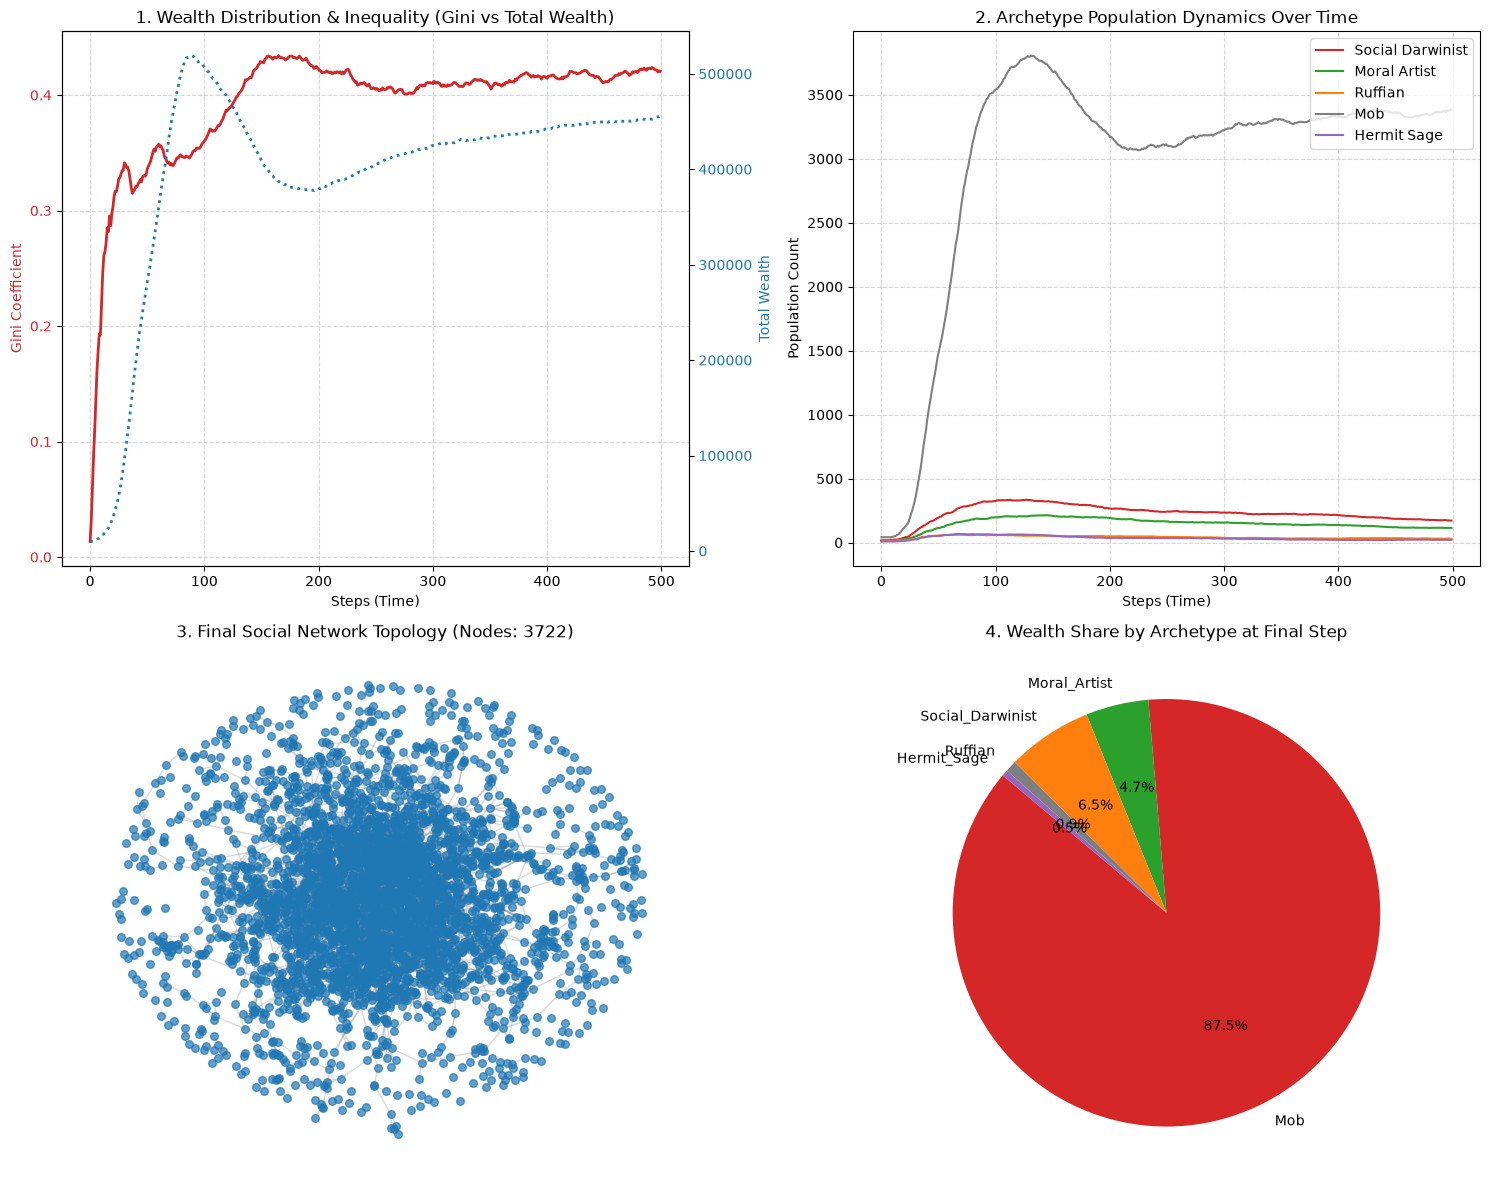

✅ Cell 8: 运行与数据分析仪表盘生成完毕！全流程构建完成。


In [8]:
# Cell 8: 模型实例化运行与多图可视化看板
# ==============================================================================

# 1. 实例化模型并绑定数据收集器
model = SocialModel()
attach_datacollector(model)

# 2. 运行仿真引擎 (默认运行 500~1000 轮)
TOTAL_STEPS = 500
print(f"🚀 开始启动社会仿真引擎，计划运行 {TOTAL_STEPS} 轮...")

for step in range(1, TOTAL_STEPS + 1):
    model.step()
    model.datacollector.collect(model)
    
    # 每 100 轮打印一次简报
    if step % 100 == 0:
        alive_cnt = len([a for a in model.agents_dict.values() if a.is_alive])
        gini = compute_gini(model)
        print(f"🔄 Step [{step}/{TOTAL_STEPS}] | 存活人口: {alive_cnt} | 基尼系数: {gini:.3f} | 科研进度: {model.global_tech_progress:.1f}")

print("✨ 仿真运行完成！正在生成可视化数据分析仪表盘...")

# 3. 数据提取与 Matplotlib 绘图
data = model.datacollector.get_model_vars_dataframe()

fig, axs = plt.subplots(2, 2, figsize=(15, 12))
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'SimHei', 'Arial'] # 兼容字体显示
plt.rcParams['axes.unicode_minus'] = False

# 图 1: 基尼系数与社会总财富演化曲线
ax1 = axs[0, 0]
color = 'tab:red'
ax1.set_xlabel('Steps (Time)')
ax1.set_ylabel('Gini Coefficient', color=color)
ax1.plot(data.index, data['Gini'], color=color, linewidth=2, label='Gini Index')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle='--', alpha=0.5)

ax1_sub = ax1.twinx()
color = 'tab:blue'
ax1_sub.set_ylabel('Total Wealth', color=color)
ax1_sub.plot(data.index, data['Total_Wealth'], color=color, linestyle=':', linewidth=2, label='Total Wealth')
ax1_sub.tick_params(axis='y', labelcolor=color)
ax1.set_title("1. Wealth Distribution & Inequality (Gini vs Total Wealth)")

# 图 2: 五类人格演化趋势 (Population Archetype Dynamics)
ax2 = axs[0, 1]
ax2.plot(data.index, data['Social_Darwinist_Count'], label='Social Darwinist', color='#d62728')
ax2.plot(data.index, data['Moral_Artist_Count'], label='Moral Artist', color='#2ca02c')
ax2.plot(data.index, data['Ruffian_Count'], label='Ruffian', color='#ff7f0e')
ax2.plot(data.index, data['Mob_Count'], label='Mob', color='#7f7f7f')
ax2.plot(data.index, data['Hermit_Sage_Count'], label='Hermit Sage', color='#9467bd')
ax2.set_xlabel('Steps (Time)')
ax2.set_ylabel('Population Count')
ax2.set_title("2. Archetype Population Dynamics Over Time")
ax2.legend(loc='upper right')
ax2.grid(True, linestyle='--', alpha=0.5)

# 图 3: 最终社交拓扑图 (Social Network Topology)
ax3 = axs[1, 0]
G = model.social_net.graph
if G.number_of_nodes() > 0:
    # 提取网络中的最大连通子图展示
    pos_net = nx.spring_layout(G, k=0.15, iterations=20)
    nx.draw_networkx_nodes(G, pos_net, ax=ax3, node_size=30, node_color='#1f77b4', alpha=0.7)
    nx.draw_networkx_edges(G, pos_net, ax=ax3, alpha=0.3, edge_color='gray')
    ax3.set_title(f"3. Final Social Network Topology (Nodes: {G.number_of_nodes()})")
else:
    ax3.text(0.5, 0.5, "No Social Connections Formed", ha='center', va='center')
ax3.axis('off')

# 图 4: 仿真终局各类人格的财富占比 (Wealth Share by Archetype)
ax4 = axs[1, 1]
wealth_by_arch = {}
for a in model.agents_dict.values():
    if a.is_alive:
        wealth_by_arch[a.archetype] = wealth_by_arch.get(a.archetype, 0) + a.resources

if wealth_by_arch:
    labels = list(wealth_by_arch.keys())
    sizes = list(wealth_by_arch.values())
    colors = ['#d62728', '#2ca02c', '#ff7f0e', '#7f7f7f', '#9467bd']
    ax4.pie(sizes, labels=labels, autopct='%1.1f%%', colors=colors, startangle=140)
    ax4.set_title("4. Wealth Share by Archetype at Final Step")

plt.tight_layout()
plt.show()

print("✅ Cell 8: 运行与数据分析仪表盘生成完毕！全流程构建完成。")